# RAPPORT / NOTEBOOK
Eser Enes         
Marfouk Omar

In [1]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np

# Configuration des options d'affichage
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

In [2]:
# Chargement des données d'observations d'oiseaux GBIF
df_obs = pd.read_csv(r"C:\SAE_GBIF\data\oiseaux_grand-est_2018-2022_GBIF.csv", sep="\t")

print(f"Nombre d'observations chargées : {len(df_obs)}")
df_obs.head()


C:\Users\Semih\AppData\Local\Temp\ipykernel_23684\4169696566.py:2: DtypeWarning: Columns (10,14,16,17,36,37,38,39,40,41,43,44,48) have mixed types. Specify dtype option on import or set low_memory=False.
  df_obs = pd.read_csv(r"C:\SAE_GBIF\data\oiseaux_grand-est_2018-2022_GBIF.csv", sep="\t")


Nombre d'observations chargées : 1562597


,gbifID,datasetKey,occurrenceID,kingdom,phylum,class,order,family,genus,species,infraspecificEpithet,taxonRank,scientificName,verbatimScientificName,verbatimScientificNameAuthorship,countryCode,locality,stateProvince,occurrenceStatus,individualCount,publishingOrgKey,decimalLatitude,decimalLongitude,coordinateUncertaintyInMeters,coordinatePrecision,elevation,elevationAccuracy,depth,depthAccuracy,eventDate,day,month,year,taxonKey,speciesKey,basisOfRecord,institutionCode,collectionCode,catalogNumber,recordNumber,identifiedBy,dateIdentified,license,rightsHolder,recordedBy,typeStatus,establishmentMeans,lastInterpreted,mediaType,issue
0,4051621400,017f23ba-bf04-4eb7-a076-04ab2e5de250,f1b52f74-e654-4dc8-888b-5a728a2d2366,Animalia,Chordata,Aves,Passeriformes,Corvidae,Corvus,Corvus corax,NaN,SPECIES,"Corvus corax Linnaeus, 1758","Corvus corax Linnaeus, 1758",NaN,FR,NaN,NaN,PRESENT,NaN,1928bdf0-f5d2-11dc-8c12-b8a03c50a862,47.69372,5.08203,4460.0,NaN,NaN,NaN,NaN,NaN,2022-01-30,30.0,1.0,2022,2482492,2482492.0,HUMAN_OBSERVATION,NaN,NaN,NaN,NaN,Alexis BRESSON (ONF),NaN,CC_BY_4_0,NaN,Alexis BRESSON (ONF),NaN,NaN,2025-07-04T19:01:07.230Z,NaN,CONTINENT_DERIVED_FROM_COORDINATES;TAXON_ID_NO...
1,4051259960,017f23ba-bf04-4eb7-a076-04ab2e5de250,bd657750-1193-4aef-a82b-5c32df1f008e,Animalia,Chordata,Aves,Passeriformes,Motacillidae,Anthus,Anthus trivialis,NaN,SPECIES,"Anthus trivialis (Linnaeus, 1758)","Anthus trivialis (Linnaeus, 1758)",NaN,FR,55239,NaN,PRESENT,NaN,1928bdf0-f5d2-11dc-8c12-b8a03c50a862,49.23770,5.41789,NaN,NaN,NaN,NaN,NaN,NaN,2018-07-13,13.0,7.0,2018,2490246,2490246.0,HUMAN_OBSERVATION,NaN,NaN,NaN,NaN,Luc BERGER (ONF),NaN,CC_BY_4_0,NaN,Luc BERGER (ONF),NaN,NaN,2025-07-04T19:01:07.230Z,NaN,CONTINENT_DERIVED_FROM_COORDINATES;TAXON_ID_NO...
2,4051268909,017f23ba-bf04-4eb7-a076-04ab2e5de250,bf005231-d388-45eb-b206-9526529d275b,Animalia,Chordata,Aves,Passeriformes,Sittidae,Sitta,Sitta europaea,NaN,SPECIES,"Sitta europaea Linnaeus, 1758","Sitta europaea Linnaeus, 1758",NaN,FR,68287,NaN,PRESENT,NaN,1928bdf0-f5d2-11dc-8c12-b8a03c50a862,47.97692,7.15034,NaN,NaN,NaN,NaN,NaN,NaN,2018-01-10,10.0,1.0,2018,2484916,2484916.0,HUMAN_OBSERVATION,NaN,NaN,NaN,NaN,Guy RITTER (ONF),NaN,CC_BY_4_0,NaN,Guy RITTER (ONF),NaN,NaN,2025-07-04T19:01:07.230Z,NaN,CONTINENT_DERIVED_FROM_COORDINATES;FOOTPRINT_W...
3,4051641991,017f23ba-bf04-4eb7-a076-04ab2e5de250,f5c41612-45d3-44c0-a94b-5e1df3d26f8b,Animalia,Chordata,Aves,Passeriformes,Troglodytidae,Troglodytes,Troglodytes troglodytes,NaN,SPECIES,"Troglodytes troglodytes (Linnaeus, 1758)","Troglodytes troglodytes (Linnaeus, 1758)",NaN,FR,68066 - Nom du site : Pt IPA Niederwald 31,NaN,PRESENT,NaN,1928bdf0-f5d2-11dc-8c12-b8a03c50a862,48.16190,7.41023,NaN,NaN,NaN,NaN,NaN,NaN,2018-05-23,23.0,5.0,2018,5231438,5231438.0,HUMAN_OBSERVATION,NaN,NaN,NaN,NaN,Francois RICHARD (ONF),NaN,CC_BY_4_0,NaN,Francois RICHARD (ONF),NaN,NaN,2025-07-04T19:01:07.230Z,NaN,CONTINENT_DERIVED_FROM_COORDINATES;FOOTPRINT_W...
4,4051661843,017f23ba-bf04-4eb7-a076-04ab2e5de250,f8b56090-0f8e-471d-91c4-0cf25264e8aa,Animalia,Chordata,Aves,Passeriformes,Corvidae,Garrulus,Garrulus glandarius,NaN,SPECIES,"Garrulus glandarius (Linnaeus, 1758)","Garrulus glandarius (Linnaeus, 1758)",NaN,FR,68066 - Nom du site : Pt IPA Niederwald 13,NaN,PRESENT,NaN,1928bdf0-f5d2-11dc-8c12-b8a03c50a862,48.16871,7.39665,NaN,NaN,NaN,NaN,NaN,NaN,2018-04-04,4.0,4.0,2018,5229493,5229493.0,HUMAN_OBSERVATION,NaN,NaN,NaN,NaN,Jacques MOREL (ONF),NaN,CC_BY_4_0,NaN,Jacques MOREL (ONF),NaN,NaN,2025-07-04T19:01:07.230Z,NaN,CONTINENT_DERIVED_FROM_COORDINATES;FOOTPRINT_W...


### Chaîne de traitement

1. Vous avez choisi de travailler au niveau des EPCI et d'utiliser les émissions de gaz à effet de serre de l'année 2022 uniquement. Pourriez-vous justifier ces choix ? (EPCI, gaz à effet de serre, 2022)


Nous avons essayé de télécharger et travaillé sur  les données occupation du
sol dans le Grand-Est en 2010 et 2019 mais on a pas réussi à télécharger les données pour les exploiter.   
Pour les Données climatologiques françaises , nous avons pas su comment exploiter les différents fichiers météorologiques.     
Nous avions donc travaillé uniquement sur les EPCI et  les ems car se sont les seuls données que nous avons su exploités puis parce qu' on voulait savoir si les données sur la pollution ont un grand rôle sur les êtres vivants.

In [3]:
# Vous n'avez pas justifié 2022. Quelle période couvre le jeu de données des oiseaux ?
print(df_obs.year.min())# Voir la date minimum du jeu de données  avec la méthode min

print(df_obs.year.max()) # Voir la date maximum du jeu de données  avec la méthode max

#utiliser les données de 2018 a 2022

2018
2022


### Jointure spatiale
2. Affichez le nombre de lignes avant et après la jointure spatiale (il faut réexécuter les cellules depuis le début). Que remarquez-vous ? Que s’est-il passé d'après vous ?


In [4]:
len(df_obs)

1562597

In [5]:
import os

# Création d'un GeoDataFrame avec les observations d'oiseaux
gdf_obs = gpd.GeoDataFrame(
    df_obs,
    geometry=gpd.points_from_xy(df_obs.decimalLongitude, df_obs.decimalLatitude),
    crs='EPSG:4326'
)

# Chargement du shapefile EPCI 2022
path_zones = r'C:\SAE_GBIF\data\ges_grand_est_epci_2022.shp'
# Configuration pour permettre à GeoPandas de recréer le fichier .shx si manquant
os.environ['SHAPE_RESTORE_SHX'] = 'YES'

gdf_zones = gpd.read_file(path_zones)

print(f"Nombre de zones EPCI : {len(gdf_zones)}")
print(f"CRS des zones AVANT traitement : {gdf_zones.crs}")

#CRS(Système de Coordonnées de Référence)
if gdf_zones.crs is None:
    gdf_zones = gdf_zones.set_crs('EPSG:2154')
print(f"CRS déjà défini : {gdf_zones.crs}")

# Convertis les coordonnées des oiseaux en géométrie de points vers le même système que les zones EPCI 
# Reprojection des OBSERVATIONS vers le CRS des zones
print(f"\nCRS des observations AVANT reprojection : {gdf_obs.crs}")
gdf_obs_proj = gdf_obs.to_crs(gdf_zones.crs)
print(f"CRS des observations APRÈS reprojection : {gdf_obs_proj.crs}")

# Vérification des bounds (coordonnées min/max)
print(f"\nCoordonnées des zones EPCI :")
print(f"   {gdf_zones.total_bounds}")
print(f"Coordonnées des observations :")
print(f"   {gdf_obs_proj.total_bounds}")

# Jointure spatiale (inner = on ne garde que les observations dans les zones)
gdf_merged = gpd.sjoin(gdf_obs_proj, gdf_zones, how='inner', predicate='within')

print(f"\nJointure spatiale terminée : {len(gdf_merged)} observations dans les zones EPCI")

gdf_merged.head()

Nombre de zones EPCI : 150
CRS des zones AVANT traitement : EPSG:3857
CRS déjà défini : EPSG:3857

CRS des observations AVANT reprojection : EPSG:4326
CRS des observations APRÈS reprojection : EPSG:3857

Coordonnées des zones EPCI :
   [ 376667.89480724 6010956.38264574  916437.3195842  6475647.1914569 ]
Coordonnées des observations :
   [ 378323.74224057 6011558.37039568  916326.38846483 6474839.64642754]

Jointure spatiale terminée : 1562448 observations dans les zones EPCI


,gbifID,datasetKey,occurrenceID,kingdom,phylum,class,order,family,genus,species,infraspecificEpithet,taxonRank,scientificName,verbatimScientificName,verbatimScientificNameAuthorship,countryCode,locality,stateProvince,occurrenceStatus,individualCount,publishingOrgKey,decimalLatitude,decimalLongitude,coordinateUncertaintyInMeters,coordinatePrecision,elevation,elevationAccuracy,depth,depthAccuracy,eventDate,day,month,year,taxonKey,speciesKey,basisOfRecord,institutionCode,collectionCode,catalogNumber,recordNumber,identifiedBy,dateIdentified,license,rightsHolder,recordedBy,typeStatus,establishmentMeans,lastInterpreted,mediaType,issue,geometry,index_right,type_zone,code_zone,lib_zone,version,annee_inv,co2_kg,ch4_kg,n2o_kg,hfc_23_kg,hfc_32_kg,hfc_125_kg,hfc_134a_k,hfc_143a_k,hfc_152a_k,hfc_227ea_,hfc_245fa_,hfc_365mfc,pfc_kg,sf6_kg,nf3_kg,prg2007_te,prg2013_te,co2_bio_kg,geom,code_epci,OBJECTID,Shape__Are,Shape__Len
0,4051621400,017f23ba-bf04-4eb7-a076-04ab2e5de250,f1b52f74-e654-4dc8-888b-5a728a2d2366,Animalia,Chordata,Aves,Passeriformes,Corvidae,Corvus,Corvus corax,NaN,SPECIES,"Corvus corax Linnaeus, 1758","Corvus corax Linnaeus, 1758",NaN,FR,NaN,NaN,PRESENT,NaN,1928bdf0-f5d2-11dc-8c12-b8a03c50a862,47.69372,5.08203,4460.0,NaN,NaN,NaN,NaN,NaN,2022-01-30,30.0,1.0,2022,2482492,2482492.0,HUMAN_OBSERVATION,NaN,NaN,NaN,NaN,Alexis BRESSON (ONF),NaN,CC_BY_4_0,NaN,Alexis BRESSON (ONF),NaN,NaN,2025-07-04T19:01:07.230Z,NaN,CONTINENT_DERIVED_FROM_COORDINATES;TAXON_ID_NO...,POINT (565728.992 6056051.173),87,EPCI,200027308,CC d'Auberive Ving,v2025,2022,1.039477e+08,1.793504e+06,130855.376260,0.012994,152.894394,198.093752,280.131440,86.075320,14.510005,4.808696,8.772631,9.105974,0.0,0.455408,0,189406.230357,190395.137079,3.238380e+07,None,200027308,88,1.693796e+09,340082.234360
1,4051259960,017f23ba-bf04-4eb7-a076-04ab2e5de250,bd657750-1193-4aef-a82b-5c32df1f008e,Animalia,Chordata,Aves,Passeriformes,Motacillidae,Anthus,Anthus trivialis,NaN,SPECIES,"Anthus trivialis (Linnaeus, 1758)","Anthus trivialis (Linnaeus, 1758)",NaN,FR,55239,NaN,PRESENT,NaN,1928bdf0-f5d2-11dc-8c12-b8a03c50a862,49.23770,5.41789,NaN,NaN,NaN,NaN,NaN,NaN,2018-07-13,13.0,7.0,2018,2490246,2490246.0,HUMAN_OBSERVATION,NaN,NaN,NaN,NaN,Luc BERGER (ONF),NaN,CC_BY_4_0,NaN,Luc BERGER (ONF),NaN,NaN,2025-07-04T19:01:07.230Z,NaN,CONTINENT_DERIVED_FROM_COORDINATES;TAXON_ID_NO...,POINT (603116.756 6315290.778),81,EPCI,200049187,CA du Grand Verdun,v2025,2022,1.612160e+08,7.686364e+05,57203.299998,0.113375,493.014679,644.719059,1042.796223,247.751244,59.769253,28.917683,28.941461,28.702123,0.0,1.800407,0,202862.329047,203015.845943,1.937627e+07,None,200049187,82,7.047933e+08,222216.770672
2,4051268909,017f23ba-bf04-4eb7-a076-04ab2e5de250,bf005231-d388-45eb-b206-9526529d275b,Animalia,Chordata,Aves,Passeriformes,Sittidae,Sitta,Sitta europaea,NaN,SPECIES,"Sitta europaea Linnaeus, 1758","Sitta europaea Linnaeus, 1758",NaN,FR,68287,NaN,PRESENT,NaN,1928bdf0-f5d2-11dc-8c12-b8a03c50a862,47.97692,7.15034,NaN,NaN,NaN,NaN,NaN,NaN,2018-01-10,10.0,1.0,2018,2484916,2484916.0,HUMAN_OBSERVATION,NaN,NaN,NaN,NaN,Guy RITTER (ONF),NaN,CC_BY_4_0,NaN,Guy RITTER (ONF),NaN,NaN,2025-07-04T19:01:07.230Z,NaN,CONTINENT_DERIVED_FROM_COORDINATES;FOOTPRINT_W...,POINT (795972.208 6103016.004),48,EPCI,246800494,CC du Pays de Rouf,v2025,2022,5.916259e+07,9.690635e+04,27907.818852,0.037392,226.639346,264.551522,502.962533,81.320084,29.770534,15.227201,14.011755,13.573328,0.0,0.527184,0,72153.933895,71398.698009,1.696219e+07,None,246800494,49,2.582949e+08,127407.752185
3,4051641991,017f23ba-bf04-4eb7-a076-04ab2e5de250,f5c41612-45d3-44c0-a94b-5e1df3d26f8b,Animalia,Chordata,Aves,Passeriformes,Troglodytidae,Troglodytes,Troglodytes troglodytes,NaN,SPECIES,"Troglodytes troglodytes (Linnaeus, 1758)","Troglodytes troglodytes (Linnaeus, 1758)",NaN,FR,68066 - Nom du site : Pt IPA Niederwald 31,NaN,PRESENT,NaN,1928bdf0-f5d2-11dc-8c12-b8a03c50a862,48.16190,7.41023,NaN,NaN,NaN,NaN,NaN,NaN,2018-05-23,23.0,5.0,2018,5231438,5231438.0,HUMAN_OBS

In [6]:
print(f"Nombre de lignes après jointure : {len(gdf_merged)}")
#Quand  faites une jointure spatiale avec gpd.sjoin(), 
# GeoPandas crée automatiquement une colonne appelée index_right qui contient l'index de la ligne correspondante dans le GeoDataFrame de droite
#  vérifier index_right
print(f"\nVérification immédiate de index_right :")
print(f"Colonnes dans gdf_merged : {gdf_merged.columns.tolist()}")
if 'index_right' in gdf_merged.columns:
    print(f"index_right existe")
    print(f"Type : {gdf_merged['index_right'].dtype}")
    print(f"Valeurs uniques : {gdf_merged['index_right'].nunique()}")
    print(f"Valeurs NaN : {gdf_merged['index_right'].isna().sum()}")
    print(f"Min : {gdf_merged['index_right'].min()}")
    print(f"Max : {gdf_merged['index_right'].max()}")
    print(f"Échantillon : {gdf_merged['index_right'].head(10).tolist()}")
    
print(f"\n Index de gdf_zones :")
print(f"Type d'index : {gdf_zones.index.dtype}")
print(f"Valeurs : {gdf_zones.index.tolist()}")

Nombre de lignes après jointure : 1562448

Vérification immédiate de index_right :
Colonnes dans gdf_merged : ['gbifID', 'datasetKey', 'occurrenceID', 'kingdom', 'phylum', 'class', 'order', 'family', 'genus', 'species', 'infraspecificEpithet', 'taxonRank', 'scientificName', 'verbatimScientificName', 'verbatimScientificNameAuthorship', 'countryCode', 'locality', 'stateProvince', 'occurrenceStatus', 'individualCount', 'publishingOrgKey', 'decimalLatitude', 'decimalLongitude', 'coordinateUncertaintyInMeters', 'coordinatePrecision', 'elevation', 'elevationAccuracy', 'depth', 'depthAccuracy', 'eventDate', 'day', 'month', 'year', 'taxonKey', 'speciesKey', 'basisOfRecord', 'institutionCode', 'collectionCode', 'catalogNumber', 'recordNumber', 'identifiedBy', 'dateIdentified', 'license', 'rightsHolder', 'recordedBy', 'typeStatus', 'establishmentMeans', 'lastInterpreted', 'mediaType', 'issue', 'geometry', 'index_right', 'type_zone', 'code_zone', 'lib_zone', 'version', 'annee_inv', 'co2_kg', 'ch4

La jointure spatiale à permit de réduire les données pour pourvoir les exploités

3. Modifiez la jointure de façon à corriger le problème et affichez sur une carte la localisation des observations qui avaient été supprimées ([documentation](https://geopandas.org/en/stable/docs/user_guide/mapping.html)). Est-ce à quoi vous vous attendiez ?

In [7]:
# Jointure en mode LEFT pour garder toutes les observations
# On utilise un nom de variable différent pour ne pas écraser gdf_merged
gdf_merged_left = gpd.sjoin(gdf_obs_proj, gdf_zones, how='left', predicate='within')

print(f"Nombre de lignes après jointure LEFT : {len(gdf_merged_left)}")
print(f"Observations DANS les zones : {gdf_merged_left.index_right.notna().sum()}")
print(f"Observations HORS zones : {gdf_merged_left.index_right.isna().sum()}")

Nombre de lignes après jointure LEFT : 1562597
Observations DANS les zones : 1562448
Observations HORS zones : 149


Nombre de points supprimés par la jointure : 149


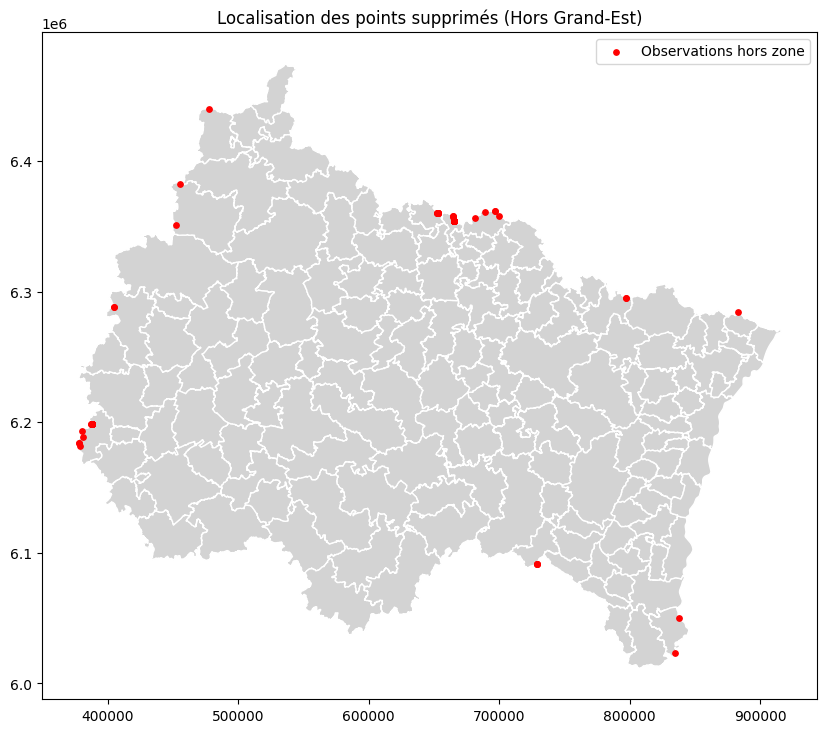

In [8]:
# 1. On utilise gdf_merged_left créé dans la cellule précédente

# 2. On isole les points "perdus" (ceux qui n'ont pas trouvé de zone correspondante)
# index_right est la colonne créée par la jointure. Si elle est vide (NaN), c'est que le point est hors zone.
points_perdus = gdf_merged_left[gdf_merged_left.index_right.isna()]

print(f"Nombre de points supprimés par la jointure : {len(points_perdus)}")

# 3. La Carte de vérification
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 10))

# A. On dessine les zones (EPCI) en gris clair pour le fond
gdf_zones.plot(ax=ax, color='lightgrey', edgecolor='white')

# B. On dessine les points perdus en ROUGE par dessus
if not points_perdus.empty:
    points_perdus.plot(ax=ax, color='red', markersize=15, label='Observations hors zone')
    plt.legend()

plt.title("Localisation des points supprimés (Hors Grand-Est)")
plt.show()

# 4. Quel traitement appliqueriez-vous à ces observations ? Justifiez.

### Année
5. Dans le notebook, vous créez une colonne `year`. Affichez les colonnes du jeu de données d'observation **avant traitement** (il faudra réexécuter la cellule qui charge en mémoire les données pour cela). Que constatez-vous ? Était-ce volontaire ?   
**Bonus.** Construire une colonne contenant l'année à partir de `eventDate` aurait pu avoir une utilité, voyez-vous laquelle ?

In [9]:
# Colonnes avant traitement
df_obs.columns

Index(['gbifID', 'datasetKey', 'occurrenceID', 'kingdom', 'phylum', 'class',
       'order', 'family', 'genus', 'species', 'infraspecificEpithet',
       'taxonRank', 'scientificName', 'verbatimScientificName',
       'verbatimScientificNameAuthorship', 'countryCode', 'locality',
       'stateProvince', 'occurrenceStatus', 'individualCount',
       'publishingOrgKey', 'decimalLatitude', 'decimalLongitude',
       'coordinateUncertaintyInMeters', 'coordinatePrecision', 'elevation',
       'elevationAccuracy', 'depth', 'depthAccuracy', 'eventDate', 'day',
       'month', 'year', 'taxonKey', 'speciesKey', 'basisOfRecord',
       'institutionCode', 'collectionCode', 'catalogNumber', 'recordNumber',
       'identifiedBy', 'dateIdentified', 'license', 'rightsHolder',
       'recordedBy', 'typeStatus', 'establishmentMeans', 'lastInterpreted',
       'mediaType', 'issue'],
      dtype='object')

**Bonus.**

6. Combien y a-t-il de lignes avec une valeur manquante dans la colonne `year` **avant traitement** ? Exécutez les deux lignes ci-dessous (issues de votre notebook). Combien y a-t-il de lignes avec une valeur manquante dans la colonne year **après traitement** ? Que s'est-il passé d'après vous ?

In [10]:
# Nombre de valeurs manquantes avant traitement
colonnes_a_garder = [
    'gbifID',
    'eventDate',        # La date
    'species',          # L'espèce
    'decimalLatitude',  # Coordonnée GPS (Latitude)
    'decimalLongitude', # Coordonnée GPS (Longitude)
    'individualCount'   # Le nombre d'individus vus
]
df_clean = df_obs[colonnes_a_garder].copy()

df_obs.year.isna().sum()

np.int64(0)

In [11]:
# Sélection des colonnes à garder
colonnes_a_garder = [
    'gbifID',
    'eventDate',        # La date
    'species',          # L'espèce
    'decimalLatitude',  # Coordonnée GPS (Latitude)
    'decimalLongitude', # Coordonnée GPS (Longitude)
    'individualCount'   # Le nombre d'individus vus (abondance)
]
df_clean = df_obs[colonnes_a_garder].copy()

# Conversion de eventDate en format datetime avec gestion des erreurs
df_clean['eventDate'] = pd.to_datetime(df_clean['eventDate'], errors='coerce')

# Extraction de l'année
df_clean['year'] = df_clean['eventDate'].dt.year

print(f"Nombre de lignes avec année valide : {df_clean['year'].notna().sum()}")
df_clean.head()


Nombre de lignes avec année valide : 1515543


,gbifID,eventDate,species,decimalLatitude,decimalLongitude,individualCount,year
0,4051621400,2022-01-30,Corvus corax,47.69372,5.08203,NaN,2022.0
1,4051259960,2018-07-13,Anthus trivialis,49.23770,5.41789,NaN,2018.0
2,4051268909,2018-01-10,Sitta europaea,47.97692,7.15034,NaN,2018.0
3,4051641991,2018-05-23,Troglodytes troglodytes,48.16190,7.41023,NaN,2018.0
4,4051661843,2018-04-04,Garrulus glandarius,48.16871,7.39665,NaN,2018.0


In [12]:
# Nombre de valeurs manquantes après traitement
df_clean.year.isna().sum()

np.int64(47054)

7. Dans votre notebook, vous appliquez la fonction `pd.to_datetime()` avec l'argument `errors='coerce'`. Réexécutez la cellule qui charge en mémoire les données d'observation. Exécutez la commande dans votre notebook sans l'argument `errors`. Pour comprendre une erreur en Python, il faut commencer par **lire la dernière ligne du message d'erreur**, qui débute généralement par le type d'erreur levée (ici, vous devriez voir `ValueError`). La suite de la ligne donne des informations sur ce qu'il s'est passé, voire donne des pistes pour résoudre le problème. Le reste du message aide à identifier la ou les lignes du code qui ont provoqué cette erreur, ce qui est très pratique lorsque vous devez déboguer un script. **En vous basant sur le message d'erreur, quel peut bien être le problème selon vous ?**  

In [13]:
# Rechargement des données pour tester sans errors='coerce'
df_obs_test = pd.read_csv(r"C:\SAE_GBIF\data\oiseaux_grand-est_2018-2022_GBIF.csv", sep="\t")
colonnes_a_garder = [
    'gbifID',
    'eventDate',        
    'species',          
    'decimalLatitude',  
    'decimalLongitude', 
    'individualCount'   
]
df_clean_test = df_obs_test[colonnes_a_garder].copy()

# Test sans errors (cela devrait générer une erreur)
try:
    df_clean_test['eventDate'] = pd.to_datetime(df_clean_test['eventDate'])
    print("Conversion réussie")
except Exception as e:
    print(f"Erreur capturée : {type(e).__name__}")
    print(f"Message : {e}")


C:\Users\Semih\AppData\Local\Temp\ipykernel_23684\1939082725.py:2: DtypeWarning: Columns (10,14,16,17,36,37,38,39,40,41,43,44,48) have mixed types. Specify dtype option on import or set low_memory=False.
  df_obs_test = pd.read_csv(r"C:\SAE_GBIF\data\oiseaux_grand-est_2018-2022_GBIF.csv", sep="\t")


Erreur capturée : ValueError
Message : unconverted data remains when parsing with format "%Y-%m-%d": "T13:15Z", at position 1826. You might want to try:
    - passing `format` if your strings have a consistent format;
    - passing `format='ISO8601'` if your strings are all ISO8601 but not necessarily in exactly the same format;
    - passing `format='mixed'`, and the format will be inferred for each element individually. You might want to use `dayfirst` alongside this.


In [14]:
# Code pd.to_datetime sans errors


8. Confirmez ou infirmez votre hypothèse grâce à la [documentation](https://techdocs.gbif.org/en/data-processing/temporal-interpretation) (paragraphe “General date and time parsing”, que vous pouvez traduire avec DeepL si besoin).

9. Écrivez une ou plusieurs lignes de code pour afficher quelques-unes des lignes qui posent problème.

In [15]:
df_obs.loc[df_obs.eventDate.str.contains("/",regex= False), "eventDate"]

503558     2019-01-01/2019-12-31
503559     2019-01-01/2019-12-31
503560     2019-01-01/2019-12-31
503561     2019-01-01/2019-12-31
503562     2018-01-01/2018-12-31
                   ...          
1148334    2022-04-11/2022-06-09
1148335    2022-04-11/2022-06-09
1148833    2022-08-01/2022-10-27
1148834    2022-08-01/2022-10-27
1149554    2021-02-22/2021-11-22
Name: eventDate, Length: 24295, dtype: object

In [16]:
pd.to_datetime("2022-05-27T15:39:04Z/2022-05-27T15:39:05Z", errors= "coerce")

NaT

In [17]:
pd.to_datetime("2022")

Timestamp('2022-01-01 00:00:00')

10. Au vu des informations collectées, comment modifieriez-vous votre code ?

**Bonus.** Concernant la carte choroplèthe représentant le nombre d'observations par EPCI (visualisation très pertinente !), sauriez-vous identifier les éventuelles limites de cette représentation ? Si vous manquez d'idées, vous pourriez trouver des éléments de réponse dans cette critique du Times des cartes diffusées pendant les élections américaines : [source](https://www.nytimes.com/interactive/2020/10/30/opinion/election-results-maps.html).

Nombre total de lignes dans gdf_merged : 1562448
 Colonnes disponibles : ['gbifID', 'datasetKey', 'occurrenceID', 'kingdom', 'phylum', 'class', 'order', 'family', 'genus', 'species', 'infraspecificEpithet', 'taxonRank', 'scientificName', 'verbatimScientificName', 'verbatimScientificNameAuthorship', 'countryCode', 'locality', 'stateProvince', 'occurrenceStatus', 'individualCount', 'publishingOrgKey', 'decimalLatitude', 'decimalLongitude', 'coordinateUncertaintyInMeters', 'coordinatePrecision', 'elevation', 'elevationAccuracy', 'depth', 'depthAccuracy', 'eventDate', 'day', 'month', 'year', 'taxonKey', 'speciesKey', 'basisOfRecord', 'institutionCode', 'collectionCode', 'catalogNumber', 'recordNumber', 'identifiedBy', 'dateIdentified', 'license', 'rightsHolder', 'recordedBy', 'typeStatus', 'establishmentMeans', 'lastInterpreted', 'mediaType', 'issue', 'geometry', 'index_right', 'type_zone', 'code_zone', 'lib_zone', 'version', 'annee_inv', 'co2_kg', 'ch4_kg', 'n2o_kg', 'hfc_23_kg', 'hfc_32_

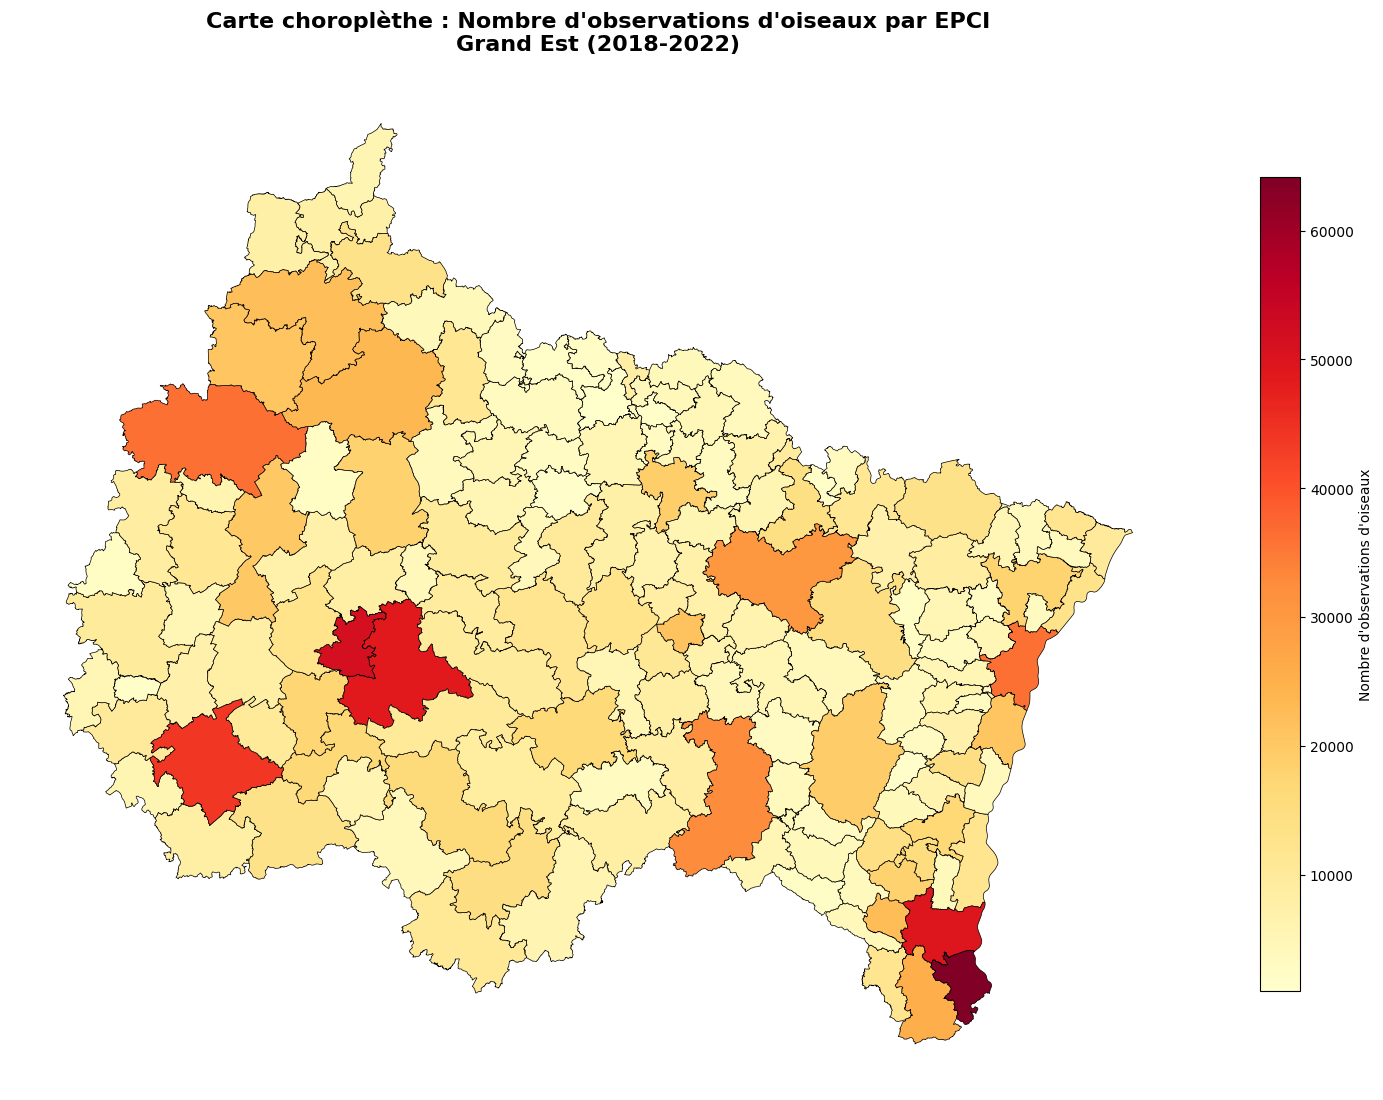


 Stat des observations par EPCI :
Nombre total d'EPCI : 150
EPCI avec observations : 150
Moyenne d'observations par EPCI : 10416
Médiane : 7055
Maximum : 64194
Minimum : 973


In [18]:
import matplotlib.pyplot as plt

print(f"Nombre total de lignes dans gdf_merged : {len(gdf_merged)}")
print(f" Colonnes disponibles : {gdf_merged.columns.tolist()}")
print(f"\n index_right existe ? {'index_right' in gdf_merged.columns}")

if 'index_right' in gdf_merged.columns:
    print(f"Type de index_right : {gdf_merged['index_right'].dtype}")
    print(f"Nombre de valeurs uniques dans index_right : {gdf_merged['index_right'].nunique()}")
    print(f"Nombre de NaN dans index_right : {gdf_merged['index_right'].isna().sum()}")
    print(f"Premières valeurs de index_right :")
    print(f"{gdf_merged['index_right'].head(10).tolist()}")
    print(f"\n index dans gdf_zones :")
    print(f" {gdf_zones.index[:10].tolist()}")

# Tentative de comptage si index_right existe
if 'index_right' in gdf_merged.columns and gdf_merged['index_right'].notna().any():
    nb_obs_par_epci = gdf_merged.groupby('index_right').size().reset_index(name='nb_observations')
    print(f"\n nbEPCI: {len(nb_obs_par_epci)} EPCI ")
    
    # 2. Joindre avec le GeoDataFrame des EPCI pour avoir les géométries
    gdf_epci_obs = gdf_zones.copy()
    gdf_epci_obs = gdf_epci_obs.reset_index()
    gdf_epci_obs = gdf_epci_obs.merge(nb_obs_par_epci, left_on='index', right_on='index_right', how='left')
    gdf_epci_obs['nb_observations'] = gdf_epci_obs['nb_observations'].fillna(0)

    # 3. Création de la carte choroplèthe
    fig, ax = plt.subplots(1, 1, figsize=(15, 12))

    gdf_epci_obs.plot(
        column='nb_observations',
        cmap='YlOrRd',
        legend=True,
        ax=ax,
        edgecolor='black',
        linewidth=0.5,
        legend_kwds={
            'label': "Nombre d'observations d'oiseaux",
            'orientation': "vertical",
            'shrink': 0.7
        }
    )

    ax.set_title("Carte choroplèthe : Nombre d'observations d'oiseaux par EPCI\nGrand Est (2018-2022)", 
                 fontsize=16, fontweight='bold', pad=20)
    ax.axis('off')

    plt.tight_layout()
    plt.show()

    # Statistiques
    print("\n Stat des observations par EPCI :")
    print(f"Nombre total d'EPCI : {len(gdf_epci_obs)}")
    print(f"EPCI avec observations : {(gdf_epci_obs['nb_observations'] > 0).sum()}")
    print(f"Moyenne d'observations par EPCI : {gdf_epci_obs['nb_observations'].mean():.0f}")
    print(f"Médiane : {gdf_epci_obs['nb_observations'].median():.0f}")
    print(f"Maximum : {gdf_epci_obs['nb_observations'].max():.0f}")
    print(f"Minimum : {gdf_epci_obs['nb_observations'].min():.0f}")


# Limites de la carte choroplèthe 
 **1. Biais de la surface géographique** 
- **Exemple** : Un grand EPCI rural avec 100 observations apparaît plus "important" qu'un petit EPCI urbain avec 1000 observations par exemple  élections US ou Les états ruraux peu peuplés semblent dominer visuellement les cartes de résultats

 **2. Absence de normalisation**
- **Problème** : La carte montre des valeurs absolues, pas des densités
- **Conséquence** : Ne tient pas compte de :
  - La **surface** de l'EPCI (km²)
  - La **population** (habitants observateurs potentiels)
  - L'**accessibilité** du territoire (zones urbaines vs rurales)

 **3. Distribution inégale de l'effort d'observation** 
- **Problème** : Plus d'observateurs = plus d'observations (pas forcément plus d'oiseaux)

 **4. Effet visuel trompeur**
- **Problème** : L'œil est attiré par les grandes zones colorées
- **Risque** : Interpréter "grande zone rouge" comme "forte biodiversité" alors que c'est surtout "grand territoire"


### Solutions 

 **1. Normaliser les données** 
- Utiliser la **densité** : observations / km²
- Utiliser des **taux** : observations / 1000 habitants
- Utiliser l'**intensité** : observations / effort de recherche

 **2. Visualisations alternatives** 

**Carte à symboles**
- Cercles dont la taille représente le nombre d'observations
- Avantage : pas de biais de surface géographique
- Déformer la carte selon la variable d'intérêt
- Les EPCI avec beaucoup d'observations deviennent plus grands
- Histogrammes
- Diagrammes en barres du TOP 10
- Nuage de points (surface vs observations)


In [19]:

# fig, ax = plt.subplots(1, 1, figsize=(15, 12))

# # 1. Dessiner le fond de carte en gris clair
# gdf_epci_obs.plot(ax=ax, color='lightgrey', edgecolor='black', linewidth=0.3, alpha=0.5)

# # 2. Ajouter les centroïdes avec des cercles 
# # Calculer les centroïdes de chaque EPCI
# gdf_epci_obs['centroid'] = gdf_epci_obs.geometry.centroid

# # Créer un GeoDataFrame avec les centroïdes
# centroids_gdf = gpd.GeoDataFrame(
#     gdf_epci_obs[['nb_observations']],
#     geometry=gdf_epci_obs['centroid'],
#     crs=gdf_epci_obs.crs
# )

# # Filtrer les EPCI avec observations
# centroids_avec_obs = centroids_gdf[centroids_gdf['nb_observations'] > 0]

# # Tracer les symboles proportionnels
# centroids_avec_obs.plot(
#     ax=ax,
#     markersize=centroids_avec_obs['nb_observations'] / 10,  # Taille proportionnelle
#     color='red',
#     alpha=0.6,
#     edgecolor='darkred',
#     linewidth=0.5
# )

# ax.set_title(" Carte  nombres d'observations Par EPCI avec symboles proportionnels", 
#              fontsize=14, fontweight='bold')
# ax.axis('off')

# # Légende manuelle
# from matplotlib.lines import Line2D
# legend_elements = [
#     Line2D([0], [0], marker='o', color='w', markerfacecolor='red', 
#            markersize=5, alpha=0.6, label='500 obs'),
#     Line2D([0], [0], marker='o', color='w', markerfacecolor='red', 
#            markersize=10, alpha=0.6, label='1000 obs'),
#     Line2D([0], [0], marker='o', color='w', markerfacecolor='red', 
#            markersize=15, alpha=0.6, label='1500 obs')
# ]
# ax.legend(handles=legend_elements, loc='lower left', title='Nombre d\'observations')

# plt.tight_layout()
# plt.show()

---

**Ajout d'information apres correction SAE**

## 1. Calcul des indicateurs par EPCI × année

- **Richesse spécifique** : nombre d'espèces différentes observées
- **Abondance totale** : nombre total d'individus observés
- **Effort d'observation** : nombre de observations
- **Abondance moyenne** : nombre moyen d'individus par observation


In [20]:
# Préparation des données pour l'analyse
# On recharge les données et on fait une jointure spatiale propre

# 1. Chargement des observations
df_obs = pd.read_csv(r"C:\SAE_GBIF\data\oiseaux_grand-est_2018-2022_GBIF.csv", sep="\t")

# 2. Sélection des colonnes essentielles
colonnes_necessaires = ['gbifID', 'eventDate', 'species', 'decimalLatitude', 
                        'decimalLongitude', 'individualCount']
df_obs_clean = df_obs[colonnes_necessaires].copy()

# 3. Conversion des dates et extraction de l'année
df_obs_clean['eventDate'] = pd.to_datetime(df_obs_clean['eventDate'], errors='coerce')
df_obs_clean['year'] = df_obs_clean['eventDate'].dt.year

# 4. Nettoyage des valeurs manquantes
df_obs_clean = df_obs_clean.dropna(subset=['species', 'decimalLatitude', 'decimalLongitude', 'year'])

# 5. Gestion de individualCount (remplacer NaN par 1)
df_obs_clean['individualCount'] = df_obs_clean['individualCount'].fillna(1)

# 6. Création du GeoDataFrame
gdf_obs = gpd.GeoDataFrame(
    df_obs_clean,
    geometry=gpd.points_from_xy(df_obs_clean.decimalLongitude, df_obs_clean.decimalLatitude),
    crs='EPSG:4326'
)

# 7. Chargement du shapefile EPCI 2022
gdf_epci = gpd.read_file(r'C:\SAE_GBIF\data\ges_grand_est_epci_2022.shp')

# 8. Reprojection et jointure spatiale
gdf_obs_proj = gdf_obs.to_crs(gdf_epci.crs)
gdf_obs_epci = gpd.sjoin(gdf_obs_proj, gdf_epci, how='inner', predicate='within')

print(f" Nombre d'observations après nettoyage : {len(gdf_obs_epci)}")
print(f" Période couverte : {int(gdf_obs_epci.year.min())} - {int(gdf_obs_epci.year.max())}")
print(f" Nombre d'EPCI concernés : {gdf_obs_epci.index_right.nunique()}")
print(f" Nombre d'espèces observées : {gdf_obs_epci.species.nunique()}")

gdf_obs_epci.head()


C:\Users\Semih\AppData\Local\Temp\ipykernel_23684\3849496753.py:5: DtypeWarning: Columns (10,14,16,17,36,37,38,39,40,41,43,44,48) have mixed types. Specify dtype option on import or set low_memory=False.
  df_obs = pd.read_csv(r"C:\SAE_GBIF\data\oiseaux_grand-est_2018-2022_GBIF.csv", sep="\t")


 Nombre d'observations après nettoyage : 1511219
 Période couverte : 2018 - 2022
 Nombre d'EPCI concernés : 150
 Nombre d'espèces observées : 417


,gbifID,eventDate,species,decimalLatitude,decimalLongitude,individualCount,year,geometry,index_right,type_zone,code_zone,lib_zone,version,annee_inv,co2_kg,ch4_kg,n2o_kg,hfc_23_kg,hfc_32_kg,hfc_125_kg,hfc_134a_k,hfc_143a_k,hfc_152a_k,hfc_227ea_,hfc_245fa_,hfc_365mfc,pfc_kg,sf6_kg,nf3_kg,prg2007_te,prg2013_te,co2_bio_kg,geom,code_epci,OBJECTID,Shape__Are,Shape__Len
0,4051621400,2022-01-30,Corvus corax,47.69372,5.08203,1.0,2022.0,POINT (565728.992 6056051.173),87,EPCI,200027308,CC d'Auberive Ving,v2025,2022,1.039477e+08,1.793504e+06,130855.376260,0.012994,152.894394,198.093752,280.131440,86.075320,14.510005,4.808696,8.772631,9.105974,0.0,0.455408,0,189406.230357,190395.137079,3.238380e+07,None,200027308,88,1.693796e+09,340082.234360
1,4051259960,2018-07-13,Anthus trivialis,49.23770,5.41789,1.0,2018.0,POINT (603116.756 6315290.778),81,EPCI,200049187,CA du Grand Verdun,v2025,2022,1.612160e+08,7.686364e+05,57203.299998,0.113375,493.014679,644.719059,1042.796223,247.751244,59.769253,28.917683,28.941461,28.702123,0.0,1.800407,0,202862.329047,203015.845943,1.937627e+07,None,200049187,82,7.047933e+08,222216.770672
2,4051268909,2018-01-10,Sitta europaea,47.97692,7.15034,1.0,2018.0,POINT (795972.208 6103016.004),48,EPCI,246800494,CC du Pays de Rouf,v2025,2022,5.916259e+07,9.690635e+04,27907.818852,0.037392,226.639346,264.551522,502.962533,81.320084,29.770534,15.227201,14.011755,13.573328,0.0,0.527184,0,72153.933895,71398.698009,1.696219e+07,None,246800494,49,2.582949e+08,127407.752185
3,4051641991,2018-05-23,Troglodytes troglodytes,48.16190,7.41023,1.0,2018.0,POINT (824903.03 6133831.614),82,EPCI,246800726,CA Colmar Agglomér,v2025,2022,4.339984e+08,3.831608e+05,86107.176096,0.433691,1869.224431,2176.257647,4046.003543,690.335140,330.669684,109.433654,120.177950,105.630313,0.0,6.273639,0,487738.082272,485036.023499,1.060024e+08,None,246800726,83,5.474049e+08,194070.314635
4,4051661843,2018-04-04,Garrulus glandarius,48.16871,7.39665,1.0,2018.0,POINT (823391.312 6134968.202),82,EPCI,246800726,CA Colmar Agglomér,v2025,2022,4.339984e+08,3.831608e+05,86107.176096,0.433691,1869.224431,2176.257647,4046.003543,690.335140,330.669684,109.433654,120.177950,105.630313,0.0,6.273639,0,487738.082272,485036.023499,1.060024e+08,None,246800726,83,5.474049e+08,194070.314635


In [21]:
# Calcul des indicateurs par EPCI × année
# On suppose que le shapefile EPCI contient une colonne identifiant l'EPCI
#  nom exact de cette colonne

print("Colonnes disponibles dans le shapefile EPCI :")
print(gdf_epci.columns.tolist())


Colonnes disponibles dans le shapefile EPCI :
['type_zone', 'code_zone', 'lib_zone', 'version', 'annee_inv', 'co2_kg', 'ch4_kg', 'n2o_kg', 'hfc_23_kg', 'hfc_32_kg', 'hfc_125_kg', 'hfc_134a_k', 'hfc_143a_k', 'hfc_152a_k', 'hfc_227ea_', 'hfc_245fa_', 'hfc_365mfc', 'pfc_kg', 'sf6_kg', 'nf3_kg', 'prg2007_te', 'prg2013_te', 'co2_bio_kg', 'geom', 'code_epci', 'OBJECTID', 'Shape__Are', 'Shape__Len', 'geometry']


In [27]:
# Calcul des 4 indicateurs par EPCI et par année
# On utilise code_epci comme identifiant 
indicateurs = gdf_obs_epci.groupby(['code_epci', 'year']).agg({
    'species': 'nunique',           # Richesse spécifique
    'gbifID': 'count',              
    'individualCount': ['sum', 'mean']  # Abondance totale et moyenne
}).reset_index()

# Renommer les colonnes (garde les noms de base sauf pour individualCount)
indicateurs.columns = ['code_epci', 'year', 'species', 'gbifID', 
                       'abondance_totale', 'abondance_moyenne']

# Arrondir l'abondance moyenne
indicateurs['abondance_moyenne'] = indicateurs['abondance_moyenne'].round(2)

# Joindre avec le nom de l'EPCI
epci_info = gdf_epci[['code_epci', 'lib_zone']].drop_duplicates()
indicateurs = indicateurs.merge(epci_info, on='code_epci', how='left')

print(f"Tableau des indicateurs créé : {len(indicateurs)} lignes")
print(f"Indicateurs calculés pour {indicateurs.code_epci.nunique()} EPCI")
print(f"Sur la période {int(indicateurs.year.min())}-{int(indicateurs.year.max())}")
indicateurs.head(10)

Tableau des indicateurs créé : 750 lignes
Indicateurs calculés pour 150 EPCI
Sur la période 2018-2022


,code_epci,year,species,gbifID,abondance_totale,abondance_moyenne,lib_zone
0,200000545,2018.0,85,191,191.0,1.00,CC des Portes de R
1,200000545,2019.0,106,310,310.0,1.00,CC des Portes de R
2,200000545,2020.0,103,666,666.0,1.00,CC des Portes de R
3,200000545,2021.0,113,433,433.0,1.00,CC des Portes de R
4,200000545,2022.0,45,122,123.0,1.01,CC des Portes de R
5,200005957,2018.0,93,365,365.0,1.00,CC de la Région de
6,200005957,2019.0,95,462,462.0,1.00,CC de la Région de
7,200005957,2020.0,106,818,818.0,1.00,CC de la Région de
8,200005957,2021.0,116,1258,1258.0,1.00,CC de la Région de
9,200005957,2022.0,33,201,201.0,1.00,CC de la Région de


## 2. Analyses temporelles 2018-2022

Nous allons analyser l'évolution de la biodiversité sur la période 2018-2022 :
- Évolution de la richesse spécifique
- Classement des EPCI (progression/déclin)
- Visualisations temporelles


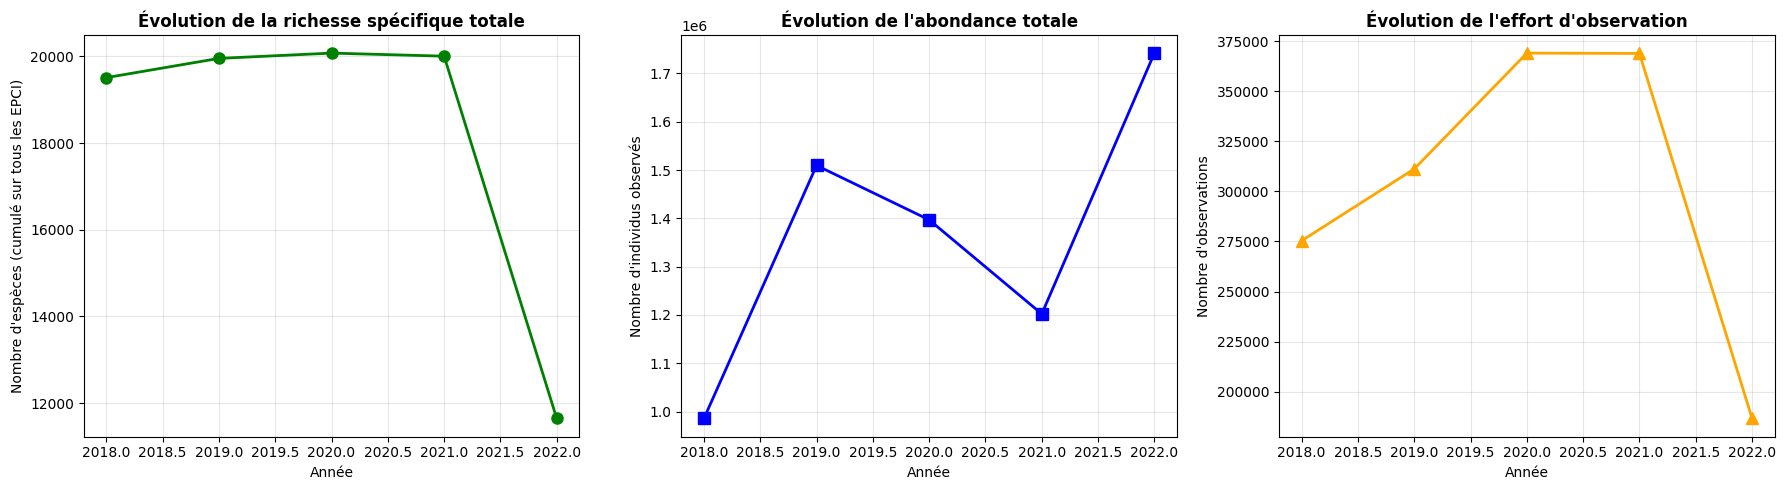


Résumé de l'évolution temporelle :
     year  species  gbifID  abondance_totale
0  2018.0    19509  275379          985918.0
1  2019.0    19953  311239         1509451.0
2  2020.0    20075  369080         1396847.0
3  2021.0    20004  368894         1202210.0
4  2022.0    11647  186627         1741917.0
Nombre d'observations  par année :
year
2018.0    275379
2019.0    311239
2020.0    369080
2021.0    368894
2022.0    186627
dtype: int64

Distribution des années :
year
2018.0    275379
2019.0    311239
2020.0    369080
2021.0    368894
2022.0    186627
Name: count, dtype: int64


'2022-12-31'

In [58]:
# Évolution globale de la richesse spécifique dans le Grand Est
evolution_globale = indicateurs.groupby('year').agg({
    'species': 'sum',
    'gbifID': 'sum',
    'abondance_totale': 'sum'
}).reset_index()

# Visualisation
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Graphique 1 : Richesse spécifique
axes[0].plot(evolution_globale['year'], evolution_globale['species'], 
             marker='o', linewidth=2, markersize=8, color='green')
axes[0].set_title('Évolution de la richesse spécifique totale', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Année')
axes[0].set_ylabel('Nombre d\'espèces (cumulé sur tous les EPCI)')
axes[0].grid(True, alpha=0.3)

# Graphique 2 : Abondance totale
axes[1].plot(evolution_globale['year'], evolution_globale['abondance_totale'], 
             marker='s', linewidth=2, markersize=8, color='blue')
axes[1].set_title('Évolution de l\'abondance totale', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Année')
axes[1].set_ylabel('Nombre d\'individus observés')
axes[1].grid(True, alpha=0.3)

# Graphique 3 : Effort d'observation
axes[2].plot(evolution_globale['year'], evolution_globale['gbifID'], 
             marker='^', linewidth=2, markersize=8, color='orange')
axes[2].set_title('Évolution de l\'effort d\'observation', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Année')
axes[2].set_ylabel('Nombre d\'observations')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\nRésumé de l'évolution temporelle :")
print(evolution_globale)

# Vérifier le nombre d'observations par année AVANT le groupby
print("Nombre d'observations  par année :")
print(gdf_obs_epci.groupby('year').size())

# Vérifier s'il y a des années manquantes 
print("\nDistribution des années :")
print(gdf_obs_epci['year'].value_counts().sort_index())

# Dernière date d'observation par espèce
df_obs.groupby('species')['eventDate'].max()

#  espèce spécifique
df_obs[df_obs['species'] == 'Corvus corax']['eventDate'].max()

Analyse donnée 2022 car on peut voir avec les graphiques un probleme survenus au cours de l'année 2022

In [56]:


# Dernière date dans le dataset brut
print("Dernière date dans le dataset brut :")
print(df_obs['eventDate'].max())

# Distribution des observations par mois en 2022
df_obs_clean['mois'] = df_obs_clean['eventDate'].dt.month
obs_2022 = df_obs_clean[df_obs_clean['year'] == 2022]
print("\nNombre d'observations par mois en 2022 :")
print(obs_2022.groupby('mois').size())

# Diagnostic des pertes au nettoyage
print("\n données 2022 \n")

# Données brutes : utiliser la colonne 'year' originale de GBIF
obs_2022_brut = df_obs[df_obs['year'] == 2022]
print(f"Observations 2022 dans le fichier brut : {len(obs_2022_brut)}")

# Après parsing de eventDate
obs_2022_clean = df_obs_clean[df_obs_clean['year'] == 2022]
print(f"Observations 2022 après nettoyage : {len(obs_2022_clean)}")

# Différence
diff = len(obs_2022_brut) - len(obs_2022_clean)
print(f"\n Observations 2022 perdues au nettoyage : {diff}")

Dernière date dans le dataset brut :
2022-12-31T19:02:24

Nombre d'observations par mois en 2022 :
mois
1     39145
2     15743
3     17583
4     18318
5     17978
6     12204
7     11359
8      9545
9      8257
10    11468
11    12372
12    12658
dtype: int64

 données 2022 

Observations 2022 dans le fichier brut : 194318
Observations 2022 après nettoyage : 186630

 Observations 2022 perdues au nettoyage : 7688


**Les causes :**
 Effet post-COVID : En 2020-2021, plus de gens confinés ont fait des observations naturalistes ? 

 Grippe ?

Comparer la richesse spécifique de 2018 à 2021 dans un TOP 

In [ ]:
# Comparer 2018 vs 2021 

richesse_2018 = indicateurs[indicateurs.year == 2018][['code_epci', 'species', 'lib_zone']].rename(
    columns={'species': 'richesse_2018'})
richesse_2021 = indicateurs[indicateurs.year == 2021][['code_epci', 'species']].rename(
    columns={'species': 'richesse_2021'})

evolution_epci_v1 = richesse_2018.merge(richesse_2021, on='code_epci', how='inner')
evolution_epci_v1['evolution_absolue'] = evolution_epci_v1['richesse_2021'] - evolution_epci_v1['richesse_2018']
evolution_epci_v1['evolution_relative'] = (evolution_epci_v1['evolution_absolue'] / evolution_epci_v1['richesse_2018'] * 100).round(2)
evolution_epci_v1 = evolution_epci_v1.sort_values('evolution_absolue', ascending=False)

print("\n TOP 10 EPCI en PROGRESSION (2018 - 2021) :")
print(evolution_epci_v1.head(10))

print("\n TOP 10 EPCI en DÉCLIN (2018 - 2021) :")
print(evolution_epci_v1.tail(10))



 TOP 10 EPCI en PROGRESSION (2018 - 2021) :
     code_epci  richesse_2018            lib_zone  richesse_2021  \
72   200068864             87  CC de la Mossig et            145   
24   200042000             43  CC Bruyères-Vallon             96   
111  245400759            128  CC du Pays du Sano            157   
112  245500327             97   CC du Sammiellois            126   
0    200000545             85  CC des Portes de R            113   
84   200070738            142   CC Mad et Moselle            170   
32   200049187            112  CA du Grand Verdun            139   
86   200070845            100  CC Orne Lorraine C            126   
21   200041515            138  CC du Bassin de Po            162   
124  245701222             38  CA du Val de Fensc             61   

     evolution_absolue  evolution_relative  
72                  58               66.67  
24                  53              123.26  
111                 29               22.66  
112                 29    

## 3. Croisement biodiversité × émissions de gaz à effet de serre

Nous allons maintenant intégrer les données d'émissions GES (2018-2022) pour analyser les corrélations avec la biodiversité.


In [61]:

# Charger les données GES pour les années 2018 à 2022
annees = [2018, 2019, 2020, 2021, 2022]
df_ges_list = []

for annee in annees:
    chemin = rf"C:\SAE_GBIF\data\ges_grand_est_epci_{annee}.csv"
    try:
        df_temp = pd.read_csv(chemin, sep=",", encoding='utf-8')
        df_temp['annee_ges'] = annee  # Renommer pour éviter confusion avec 'year'
        df_ges_list.append(df_temp)
        print(f" Chargé : {annee} ({len(df_temp)} lignes)")
    except Exception as e:
        print(f"Erreur lors du chargement de {annee} : {e}")

df_ges = pd.concat(df_ges_list, ignore_index=True)

print(f"\n Total : {len(df_ges)} lignes d'émissions GES chargées")
print(f"\nColonnes GES disponibles :")
print(df_ges.columns.tolist())
df_ges.head()

 Chargé : 2018 (150 lignes)
 Chargé : 2019 (150 lignes)
 Chargé : 2020 (150 lignes)
 Chargé : 2021 (150 lignes)
 Chargé : 2022 (150 lignes)

 Total : 750 lignes d'émissions GES chargées

Colonnes GES disponibles :
['OBJECTID', 'type_zone', 'code_zone', 'lib_zone', 'version', 'annee_inv', 'co2_kg', 'ch4_kg', 'n2o_kg', 'hfc_23_kg', 'hfc_32_kg', 'hfc_125_kg', 'hfc_134a_kg', 'hfc_143a_kg', 'hfc_152a_kg', 'hfc_227ea_kg', 'hfc_245fa_kg', 'hfc_365mfc_kg', 'pfc_kg', 'sf6_kg', 'nf3_kg', 'prg2007_teqco2', 'prg2013_teqco2', 'co2_bio_kg', 'geom', 'GlobalID', 'Shape__Area', 'Shape__Length', 'annee_ges', 'code_epci']


,OBJECTID,type_zone,code_zone,lib_zone,version,annee_inv,co2_kg,ch4_kg,n2o_kg,hfc_23_kg,hfc_32_kg,hfc_125_kg,hfc_134a_kg,hfc_143a_kg,hfc_152a_kg,hfc_227ea_kg,hfc_245fa_kg,hfc_365mfc_kg,pfc_kg,sf6_kg,nf3_kg,prg2007_teqco2,prg2013_teqco2,co2_bio_kg,geom,GlobalID,Shape__Area,Shape__Length,annee_ges,code_epci
0,1,EPCI,200000545,CC des Portes de Romilly sur Seine,v2023,2018,53917090.0,91709.88,25204.49,0.176975,228.5046,390.4614,698.7988,172.37480,21.52272,12.961380,15.86156,12.911780,0.0,3.627717,0,67167.75,66450.28,10925990.0,0103000020DB0B000001000000C2080000285C8FFAEC6A...,8061e6ab-4e47-44dc-b646-19cc26cf18a4,1.049026e+08,62482.812061,2018,NaN
1,2,EPCI,200005957,CC de la Région de Rambervillers,v2023,2018,85222540.0,2695026.00,56881.51,0.088929,111.0818,168.8015,537.4440,60.28979,18.97359,6.988491,10.04548,9.244915,0.0,2.568846,0,171355.10,177458.80,207777200.0,0103000020DB0B000001000000BC0C0000903177C55925...,38ba39a2-b6c9-48ba-8086-a220ae29cbb2,3.288356e+08,115650.624232,2018,NaN
2,3,EPCI,200006716,CC du Nogentais,v2023,2018,168453900.0,1796364.00,103727.60,0.172039,178.7414,262.1322,689.4554,87.18557,22.44148,11.466370,13.74183,12.478220,0.0,3.312418,0,246829.40,248650.00,56332900.0,0103000020DB0B000001000000DB120000BC0512CCEF3F...,b6c2bd2f-5fa6-41e4-80b4-b147d31d8e3a,2.957118e+08,126262.882263,2018,NaN
3,4,EPCI,200013050,CC Sauer-Pechelbronn,v2023,2018,39492160.0,413198.50,23272.64,0.081730,134.7525,203.7344,523.0577,73.14410,17.29768,7.891138,11.70666,10.372940,0.0,3.422241,0,58763.41,59125.74,29667250.0,0103000020DB0B000001000000A70B0000B8D100BE59B6...,3106c234-9175-41d9-a726-6df715eda9af,1.976077e+08,103226.258054,2018,NaN
4,5,EPCI,200027308,CC d'Auberive Vingeanne et Montsaugeonnais,v2023,2018,100247200.0,1959904.00,143313.00,0.058415,79.6432,201.7172,895.8264,136.13210,25.40337,5.240031,11.65733,13.483520,0.0,1.639479,0,194682.30,195695.00,32107500.0,0103000020DB0B000001000000BD11000038894178D531...,78c338e2-8898-4189-a684-7396577b333b,7.652099e+08,228670.464028,2018,NaN


**Identifier les colonnes communes pour la jointure**

In [63]:
print("Colonnes dans indicateurs :")
print(indicateurs.columns.tolist())

print("\nColonnes dans df_ges :")
print(df_ges.columns.tolist())

# Vérifier que les codes EPCI correspondent
print("\n Vérification des clés de jointure ")
print(f"Codes EPCI dans indicateurs : {indicateurs['code_epci'].nunique()} uniques")
print(f"Échantillon : {indicateurs['code_epci'].head(3).tolist()}")

print(f"\nCodes dans df_ges (code_zone) : {df_ges['code_zone'].nunique()} uniques")
print(f"Échantillon : {df_ges['code_zone'].head(3).tolist()}")

Colonnes dans indicateurs :
['code_epci', 'year', 'species', 'gbifID', 'abondance_totale', 'abondance_moyenne', 'lib_zone', 'richesse_normalisee']

Colonnes dans df_ges :
['OBJECTID', 'type_zone', 'code_zone', 'lib_zone', 'version', 'annee_inv', 'co2_kg', 'ch4_kg', 'n2o_kg', 'hfc_23_kg', 'hfc_32_kg', 'hfc_125_kg', 'hfc_134a_kg', 'hfc_143a_kg', 'hfc_152a_kg', 'hfc_227ea_kg', 'hfc_245fa_kg', 'hfc_365mfc_kg', 'pfc_kg', 'sf6_kg', 'nf3_kg', 'prg2007_teqco2', 'prg2013_teqco2', 'co2_bio_kg', 'geom', 'GlobalID', 'Shape__Area', 'Shape__Length', 'annee_ges', 'code_epci']

 Vérification des clés de jointure 
Codes EPCI dans indicateurs : 150 uniques
Échantillon : [200000545, 200000545, 200000545]

Codes dans df_ges (code_zone) : 150 uniques
Échantillon : [200000545, 200005957, 200006716]


**Effectuer la jointure biodiversité  avec  GES**


In [68]:
# ÉTAPE 3 : Effectuer la jointure biodiversité × GES

# D'abord, vérifions les types de données des clés
print("Vérification des types avant jointure ")
print(f"Type code_epci dans indicateurs : {indicateurs['code_epci'].dtype}")
print(f"Type code_zone dans df_ges : {df_ges['code_zone'].dtype}")

# Convertir en string  pour éviter les problèmes
indicateurs['code_epci'] = indicateurs['code_epci'].astype(str)
df_ges['code_zone'] = df_ges['code_zone'].astype(str)

# Convertir year en int
indicateurs['year'] = indicateurs['year'].astype(int)
df_ges['annee_ges'] = df_ges['annee_ges'].astype(int)

# Effectuer la jointure
df_croisement = indicateurs.merge(
    df_ges,
    left_on=['code_epci', 'year'],
    right_on=['code_zone', 'annee_ges'],
    how='inner'
)

# Renommer les colonnes pour plus de clarté (supprimer les suffixes _x et _y)
df_croisement = df_croisement.rename(columns={
    'code_epci_x': 'code_epci',
    'lib_zone_x': 'lib_zone'
})

# Supprimer les colonnes dupliquées inutiles
colonnes_a_supprimer = ['code_epci_y', 'lib_zone_y', 'code_zone', 'annee_ges']
df_croisement = df_croisement.drop(columns=[c for c in colonnes_a_supprimer if c in df_croisement.columns])

print(f"\n Croisement réussi : {len(df_croisement)} lignes")
print(f" EPCI avec données complètes : {df_croisement['code_epci'].nunique()}")
print(f" Années couvertes : {sorted(df_croisement['year'].unique())}")

print(f"\nColonnes après nettoyage :")
print(df_croisement.columns.tolist())

df_croisement.head()

Vérification des types avant jointure 
Type code_epci dans indicateurs : object
Type code_zone dans df_ges : object

 Croisement réussi : 750 lignes
 EPCI avec données complètes : 150
 Années couvertes : [np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022)]

Colonnes après nettoyage :
['code_epci', 'year', 'species', 'gbifID', 'abondance_totale', 'abondance_moyenne', 'lib_zone', 'richesse_normalisee', 'OBJECTID', 'type_zone', 'version', 'annee_inv', 'co2_kg', 'ch4_kg', 'n2o_kg', 'hfc_23_kg', 'hfc_32_kg', 'hfc_125_kg', 'hfc_134a_kg', 'hfc_143a_kg', 'hfc_152a_kg', 'hfc_227ea_kg', 'hfc_245fa_kg', 'hfc_365mfc_kg', 'pfc_kg', 'sf6_kg', 'nf3_kg', 'prg2007_teqco2', 'prg2013_teqco2', 'co2_bio_kg', 'geom', 'GlobalID', 'Shape__Area', 'Shape__Length']


,code_epci,year,species,gbifID,abondance_totale,abondance_moyenne,lib_zone,richesse_normalisee,OBJECTID,type_zone,version,annee_inv,co2_kg,ch4_kg,n2o_kg,hfc_23_kg,hfc_32_kg,hfc_125_kg,hfc_134a_kg,hfc_143a_kg,hfc_152a_kg,hfc_227ea_kg,hfc_245fa_kg,hfc_365mfc_kg,pfc_kg,sf6_kg,nf3_kg,prg2007_teqco2,prg2013_teqco2,co2_bio_kg,geom,GlobalID,Shape__Area,Shape__Length
0,200000545,2018,85,191,191.0,1.00,CC des Portes de R,445.026178,1,EPCI,v2023,2018,5.391709e+07,91709.880000,25204.490,0.176975,228.504600,390.46140,698.798800,172.374800,21.522720,12.961380,15.861560,12.91178,0.0,3.627717,0,67167.750000,66450.280000,1.092599e+07,0103000020DB0B000001000000C2080000285C8FFAEC6A...,8061e6ab-4e47-44dc-b646-19cc26cf18a4,1.049026e+08,62482.812061
1,200000545,2019,106,310,310.0,1.00,CC des Portes de R,341.935484,1,EPCI,v2023,2019,5.131441e+07,89584.010000,24939.560,0.129741,239.571500,365.39840,582.158300,135.468100,19.657210,12.525520,16.834280,14.19823,0.0,3.262875,0,64012.330000,63308.120000,1.113377e+07,0103000020DB0B000001000000C2080000285C8FFAEC6A...,51e3379f-3994-4091-bd03-3c61714e6641,1.049026e+08,62482.812061
2,200000545,2020,103,666,666.0,1.00,CC des Portes de R,154.654655,1,EPCI,v2023,2020,4.599242e+07,84193.690000,24453.480,0.098495,225.330000,306.75670,507.601100,92.137730,17.538630,12.251500,17.345960,14.67026,0.0,3.270955,0,57895.040000,57205.350000,1.019861e+07,0103000020DB0B000001000000C2080000285C8FFAEC6A...,5a1a8b7c-88e9-4154-af96-c6f810e8a359,1.049026e+08,62482.812061
3,200000545,2021,113,433,433.0,1.00,CC des Portes de R,260.969977,1,EPCI,v2023,2021,5.131254e+07,88208.650000,24523.480,0.107068,223.386100,322.86330,531.194600,109.458400,18.454360,11.946740,16.848500,14.26571,0.0,3.266915,0,63500.950000,62818.360000,1.266875e+07,0103000020DB0B000001000000C2080000285C8FFAEC6A...,a0d526be-099b-4966-9ce7-12ea13cf0de6,1.049026e+08,62482.812061
4,200000545,2022,45,122,123.0,1.01,CC des Portes de R,368.852459,93,EPCI,v2025,2022,4.417863e+07,115626.476407,22656.964,0.043351,222.774276,208.74503,520.992015,31.706583,47.622644,13.877678,18.693797,13.94307,0.0,0.869858,0,55690.185467,55163.578755,1.044025e+07,NaN,NaN,2.389020e+08,94293.590010


**Analyse des corrélations biodiversité × émissions GES**


In [77]:
# Colonnes d'émissions disponibles
cols_emissions = ['co2_kg', 'ch4_kg', 'n2o_kg', 'prg2013_teqco2']

print(" Corrélations richesse spécifique × émissions GES :\n")

correlations = {}
for col in cols_emissions:
    if col in df_croisement.columns:
        data_valid = df_croisement[['species', col]].dropna()
        if len(data_valid) > 10:
            corr = data_valid['species'].corr(data_valid[col])
            correlations[col] = corr
            signe = "+" if corr > 0 else ""
            print(f"   {col}: {signe}{corr:.3f}")


 Corrélations richesse spécifique × émissions GES :

   co2_kg: +0.244
   ch4_kg: +0.249
   n2o_kg: +0.417
   prg2013_teqco2: +0.281


Nos résultats ne montrent PAS cette relation attendue, ce qu'on attendrait :
 corrélation négative (plus de pollution → moins d'espèces)

- Nos données ne permettent pas de confirmer ou infirmer l'impact des GES sur la biodiversité car elles sont biaisées par l'effort d'observation inégal entre les territoires.

**Apres normalisation**

La normalisation consiste à ajuster une mesure pour éliminer un biais ou rendre les données comparables.

Comparer directement le nombre d'espèces entre EPCI est biaisé car certains EPCI ont plus d'observateurs que d'autres.

In [76]:
# Normaliser par l'effort d'observation
df_croisement['richesse_normalisee'] = df_croisement['species'] / df_croisement['gbifID'] * 1000
# Recalculer les corrélations avec la richesse normalisée
print(" Corrélations richesse normalisée  émissions GES :\n")
for col in ['co2_kg', 'ch4_kg', 'n2o_kg', 'prg2013_teqco2']:
    if col in df_croisement.columns:
        data_valid = df_croisement[['richesse_normalisee', col]].dropna()
        if len(data_valid) > 10:
            corr = data_valid['richesse_normalisee'].corr(data_valid[col])
            signe = "+" if corr > 0 else ""
            print(f"   {col}: {signe}{corr:.3f}")

 Corrélations richesse normalisée  émissions GES :

   co2_kg: -0.246
   ch4_kg: -0.225
   n2o_kg: -0.323
   prg2013_teqco2: -0.274


Plus d'émissions GES → Moins de biodiversité (richesse spécifique)
C'est cohérent avec l'hypothèse scientifique 

Cependant corrélations restent faibles d'autres  facteurs en jeu comme l'habitat, climat, urbanisation...